In [24]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [ ]:
load_gmx_plumed()

In [25]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ

/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ


# 1a 🌡️ Temperature Screening Protocol

To estimate an appropriate upper temperature before setting up **solute tempering / HREMD**, I ran short independent protein simulations across a temperature ladder.

## What I did

- Prepared simulations at **300, 400, 500, 600, 700, 800, 900, and 1000 K**
- Created separate folders under `Temp/T{T}`
- Edited `ref_t` in `grompp.mdp` for each temperature using automated folder-specific temperature assignment.
- Used `b4md.gro` and `topol.top` to generate each `.tpr` (refer to Gromacs_Solvated_MD_HPC repository to find out how to generate these files)
- Ran each temperature independently for **10ns**

✅ Goal: identify the lowest temperature showing barrier crossing and reversible sampling.

In [6]:
%%writefile run_temps.py

import os
import subprocess
import re
from contextlib import contextmanager

@contextmanager
def cd(newdir):
    prevdir = os.getcwd()
    os.chdir(newdir)
    try:
        yield
    finally:
        os.chdir(prevdir)

def sanitize_env_for_mpi():
    for k in list(os.environ.keys()):
        if k.startswith("BASH_FUNC_") or k in ("ml", "module", "which", "setup_accre_software_stack"):
            os.environ.pop(k, None)

def run_mpi(command):
    mpicmd = "mpirun"
    if "SLURM_JOB_ID" not in os.environ:
        mpicmd += " --oversubscribe"
    subprocess.run(f"{mpicmd} {command}", shell=True, check=True)

def popen_mpi(command, logfile):
    mpicmd = "mpirun"
    if "SLURM_JOB_ID" not in os.environ:
        mpicmd += " --oversubscribe"

    f = open(logfile, "w")
    p = subprocess.Popen(
        f"{mpicmd} {command}",
        shell=True,
        stdout=f,
        stderr=subprocess.STDOUT
    )
    return p, f

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    result = subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True,
        check=True
    )

    for line in result.stdout.splitlines():
        if "=" in line:
            key, _, value = line.partition("=")
            os.environ[key] = value

workdir = os.getcwd()
print(f"📂 Using current directory: {workdir}")

print("🔄 Loading GROMACS + PLUMED environment...")
load_gmx_plumed()
sanitize_env_for_mpi()
print("✅ Environment ready.")

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

replica_dirs = []

for T in Ts:
    replica_dir = os.path.join("Temp", f"T{T}")
    os.makedirs(replica_dir, exist_ok=True)

    with open("grompp.mdp") as f_in, open(os.path.join(replica_dir, "grompp.mdp"), "w") as f_out:
        for line in f_in:
            raw = line.rstrip("\n")
            if re.match(r"^\s*ref[_-]t\s*=", raw):
                base, *comment = raw.split(";", 1)
                indent = re.match(r"^\s*", base).group(0)
                raw = f"{indent}ref_t                   = {T}     {T}"
                if comment:
                    raw += " ;" + comment[0]
            print(raw, file=f_out)

    with cd(replica_dir):
        run_mpi("-np 1 gmx_mpi grompp -f grompp.mdp -c ../../b4md.gro -p ../../protein.top")
        replica_dirs.append(os.path.abspath(os.getcwd()))

# Run all temperatures in parallel
procs = []

for d in replica_dirs:
    print(f"▶️ Launching mdrun in {d} ...")
    with cd(d):
        logfile = os.path.join(d, "mdrun.log")
        p, f = popen_mpi(
            "-np 1 gmx_mpi mdrun -nsteps 5000000 -pin on -ntomp 12",
            logfile
        )
        procs.append((d, p, f))

# Wait for all runs to finish
failed = []

for d, p, f in procs:
    ret = p.wait()
    f.close()

    if ret == 0:
        print(f"✅ Finished: {d}")
    else:
        print(f"❌ Failed: {d}")
        failed.append(d)

if failed:
    print("Some simulations failed:")
    for d in failed:
        print(d)
    raise SystemExit(1)

print("🎉 All temperature simulations finished.")

Overwriting run_temps.py


Run the python script 

In [8]:
!python run_temps.py

📂 Using current directory: /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
🔄 Loading GROMACS + PLUMED environment...
✅ Environment ready.
               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/Temp/T300
Command line:
  gmx_mpi grompp -f grompp.mdp -c ../../b4md.gro -p ../../protein.top

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Setting the LD random seed to -33767426

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded ne

Optional: PyMOL Visualization 🎬

Generate multi-frame PDB files from trajectories for visualization in **PyMOL**.

✨ Frames were centered, PBC corrected, and written every 50 frames to compare temperature-dependent conformational changes.

In [27]:
import os
import subprocess

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

procs = []

for T in Ts:
    d = os.path.join("Temp", f"T{T}")

    cmd = (
        f"cd {d} && "
        f"echo 1 1 | gmx_mpi trjconv "
        f"-f traj_comp.xtc "
        f"-s topol.tpr "
        f"-center "
        f"-pbc mol "
        f"-skip 50 "
        f"-o T{T}_movie_skip50.pdb "
        f"> trjconv_movie.log 2>&1"
    )

    print(f"▶️ Launching T{T}")
    p = subprocess.Popen(cmd, shell=True)
    procs.append((T, d, p))

failed = []

for T, d, p in procs:
    ret = p.wait()

    if ret == 0:
        print(f"✅ Finished T{T}: {d}/T{T}_movie_skip50.pdb")
    else:
        print(f"❌ Failed T{T}. Check {d}/trjconv_movie.log")
        failed.append(T)

if failed:
    print("Failed temperatures:", failed)
else:
    print("🎉 All multi-frame PDB files created.")

▶️ Launching T300
▶️ Launching T400
▶️ Launching T500
▶️ Launching T600
▶️ Launching T700
▶️ Launching T800
▶️ Launching T900
▶️ Launching T1000


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

✅ Finished T300: Temp/T300/T300_movie_skip50.pdb
✅ Finished T400: Temp/T400/T400_movie_skip50.pdb
✅ Finished T500: Temp/T500/T500_movie_skip50.pdb
✅ Finished T600: Temp/T600/T600_movie_skip50.pdb
✅ Finished T700: Temp/T700/T700_movie_skip50.pdb
✅ Finished T800: Temp/T800/T800_movie_skip50.pdb
✅ Finished T900: Temp/T900/T900_movie_skip50.pdb
✅ Finished T1000: Temp/T1000/T1000_movie_skip50.pdb
🎉 All multi-frame PDB files created.


## Analysis 📊

For each temperature simulation:

- Centered and unwrapped protein trajectories (`trjconv`)
- Calculated **radius of gyration (Rg)** (`gyrate`)
- Calculated **protein RMSD** relative to the starting structure (`rms`)

✨ Rg and RMSD trends were used to assess temperature-dependent conformational changes and identify temperatures capable of overcoming structural barriers.

Note this runs calculations in parallel make sure that you have enough cores

In [ ]:
import os
import subprocess

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

for T in Ts:

    replica_dir = f"Temp/T{T}"

    tpr = f"{replica_dir}/topol.tpr"
    xtc = f"{replica_dir}/traj_comp.xtc"

    centered_xtc = f"{replica_dir}/centered_protein.xtc"
    gyrate_xvg = f"{replica_dir}/gyration.xvg"
    rmsd_xvg = f"{replica_dir}/rmsd.xvg"

    if not os.path.exists(tpr):
        print(f"❌ Missing: {tpr}")
        continue

    if not os.path.exists(xtc):
        print(f"❌ Missing: {xtc}")
        continue

    print(f"▶️ Processing T{T}")

    # Center protein and output protein-only trajectory
    subprocess.run(
        f'printf "1\n1\n" | gmx_mpi trjconv -f {xtc} -s {tpr} -o {centered_xtc} -center -pbc nojump',
        shell=True,
        check=True
    )

    # Radius of gyration for Protein
    subprocess.run(
        f'printf "1\n" | gmx_mpi gyrate -f {centered_xtc} -s {tpr} -o {gyrate_xvg}',
        shell=True,
        check=True
    )

    # RMSD for Protein fitted to Protein
    subprocess.run(
        f'printf "1\n1\n" | gmx_mpi rms -f {centered_xtc} -s {tpr} -o {rmsd_xvg}',
        shell=True,
        check=True
    )
    print(f"✅ Finished T{T}")

print("🎉 Finished centered trajectory, Rg, and RMSD analysis.")

▶️ Processing T300


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi gyrate -f Temp/T300/centered_protein.xtc -s Temp/T300/topol.tpr -o Temp/T300/gyration.xvg

Reading file Temp/T300/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file Temp/T300/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 36986 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (    MainChain+H) has  1348 elements
Group     8 (      SideChain) has  3074 elements
Group     9 (

Selected 1: 'Protein'


...

/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Selected 1: 'Protein'


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T1000
🎉 Finished centered trajectory, Rg, and RMSD analysis.


Reading frame    1400 time 7000.000   

GROMACS reminds you: "You're About to Hurt Somebody" (Jazzy Jeff)



Plots to Analyze the RMSD and Rg across all temperatures analyzed

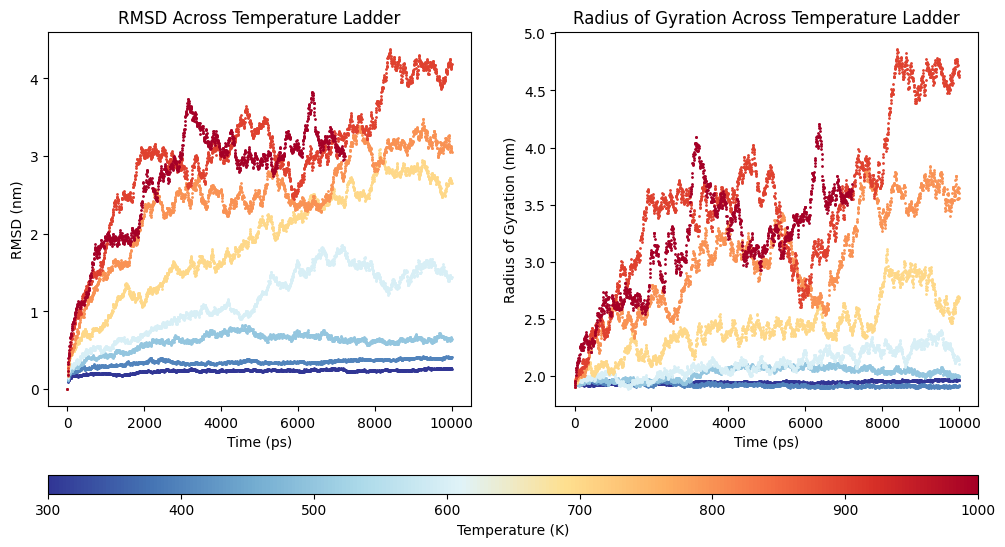

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# ===================== COLORS ============================
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# ===================== TEMPERATURES ======================
# =========================================================

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

norm = Normalize(vmin=min(Ts), vmax=max(Ts))

# =========================================================
# ===================== XVG READER ========================
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# ===================== LOAD DATA =========================
# =========================================================

rmsd_data = []
rg_data = []

for T in Ts:

    rmsd_file = f"Temp/T{T}/rmsd.xvg"
    rg_file   = f"Temp/T{T}/gyration.xvg"

    rmsd_data.append(read_xvg(rmsd_file))
    rg_data.append(read_xvg(rg_file))

# =========================================================
# ===================== FIGURE ============================
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# ===================== RMSD ==============================
# =========================================================

for i, T in enumerate(Ts):

    color = CMAP(norm(T))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Temperature Ladder")

# =========================================================
# ===================== Rg ================================
# =========================================================

for i, T in enumerate(Ts):

    color = CMAP(norm(T))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Temperature Ladder")

# =========================================================
# ===================== COLORBAR ==========================
# =========================================================

sm = ScalarMappable(
    norm=norm,
    cmap=CMAP
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Temperature (K)")

# =========================================================
# ===================== OUTPUT ============================
# =========================================================

plt.show()

Inference 🔍

Lower temperatures (**300–500 K**) largely remained within the starting basin, whereas transitions toward ~**1.5 nm RMSD** emerged near **700 K**, consistent with the partially unfolded intermediate previously identified from SMOG simulations.

✨ As these simulations were only **10 ns**, the next step is to perform longer simulations (**~100 ns**) while narrowing the temperature range below **700 K** to better identify the onset of intermediate-state.
*****************************

## 1b🌡️ Narrowing Temperature Screening

Based on the initial temperature ladder, a second round of simulations was performed to refine the transition region associated with intermediate-state formation.

### Protocol

- Selected a narrower temperature range of **310–530 K** in **10 K increments**
- This range was chosen **arbitrarily below 700 K** following the initial screening results
- Generated independent temperature directories under `1b/T{T}`
- Modified `ref_t` in `grompp.mdp` for each temperature
- Generated temperature-specific `.tpr` files using `b4md.gro` and `topol.top`

✨ The goal was to more precisely identify conditions associated with intermediate-state sampling.

In [ ]:
import os
import subprocess
import re
from contextlib import contextmanager

@contextmanager
def cd(newdir):
    prevdir = os.getcwd()
    os.chdir(newdir)
    try:
        yield
    finally:
        os.chdir(prevdir)

def sanitize_env_for_mpi():
    for k in list(os.environ.keys()):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_mpi(command):

    mpicmd = "mpirun"

    if "SLURM_JOB_ID" not in os.environ:
        mpicmd += " --oversubscribe"

    full_cmd = f"{mpicmd} {command}"

    subprocess.run(
        full_cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def load_gmx_plumed():

    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2

    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC

    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH

    env
    """

    result = subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True,
        check=True
    )

    for line in result.stdout.splitlines():
        if "=" in line:
            key, _, value = line.partition("=")
            os.environ[key] = value

workdir = os.getcwd()

load_gmx_plumed()
sanitize_env_for_mpi()

Ts = list(range(310, 531, 10))

input_gro = os.path.join(workdir, "b4md.gro")
input_top = os.path.join(workdir, "topol.top")
input_mdp = os.path.join(workdir, "grompp.mdp")

main_replica_dir = os.path.join(workdir, "1b")
os.makedirs(main_replica_dir, exist_ok=True)

for T in Ts:

    replica_dir = os.path.join(main_replica_dir, f"T{T}")
    os.makedirs(replica_dir, exist_ok=True)

    output_mdp = os.path.join(replica_dir, "grompp.mdp")

    with open(input_mdp) as f_in, open(output_mdp, "w") as f_out:

        for line in f_in:

            raw = line.rstrip("\n")

            if re.match(r"^\s*ref[_-]t\s*=", raw):

                base, *comment = raw.split(";", 1)

                indent = re.match(r"^\s*", base).group(0)

                raw = f"{indent}ref_t                   = {T}     {T}"

                if comment:
                    raw += " ;" + comment[0]

            print(raw, file=f_out)

    with cd(replica_dir):

        run_mpi(
            f"-np 1 gmx_mpi grompp "
            f"-f grompp.mdp "
            f"-c {input_gro} "
            f"-p {input_top} "
            f"-o md.tpr"
        )

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T380
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5


Setting the LD random seed to 1727787983

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 380 K

Calculated rlist for 1x1 atom pair-list as 0.943 nm, buffer size 0.043 nm

Set rlist, assuming 4x4 atom pair-list, to 0.902 nm, buffer size 0.002 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

GROMACS reminds you: "When I got my first job as a programmer there were quite a number of women doing programming because there was no computer science education and people were hired from many different fields if it seemed like they could do the work. It was better then, probably, in terms of proportions, not necessarily in women being paid as much as men and so forth, but definitely, there were women around." (Barbara Liskov)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T390
Command line:
  gmx_mpi grompp -f grompp.mdp -c /

Setting the LD random seed to -69534019

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 390 K

Calculated rlist for 1x1 atom pair-list as 0.944 nm, buffer size 0.044 nm

Set rlist, assuming 4x4 atom pair-list, to 0.902 nm, buffer size 0.002 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Yeah, a Wuzz, Or a Jerk" (F. Black)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T400
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 

...


GROMACS reminds you: "I had trouble with physics in college. When I signed up I thought it said psychics." (Greg Tamblyn)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T520
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5


Setting the LD random seed to -142632710

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 520 K

Calculated rlist for 1x1 atom pair-list as 0.956 nm, buffer size 0.056 nm

Set rlist, assuming 4x4 atom pair-list, to 0.910 nm, buffer size 0.010 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Come on boys, Let's push it hard" (P.J. Harvey)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T530
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-

Setting the LD random seed to 670487550

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 530 K

Calculated rlist for 1x1 atom pair-list as 0.957 nm, buffer size 0.057 nm

Set rlist, assuming 4x4 atom pair-list, to 0.911 nm, buffer size 0.011 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Come on boys, Let's push it hard" (P.J. Harvey)



You can either run on jupyternotebook (use A6000 with 4 GPUs) itself or submit slurm script 

In [ ]:
import subprocess

slurm_script = """#!/bin/bash
#SBATCH --job-name=6ONJ_TempTest
#SBATCH --mail-user=mithun.nag.karadi.giridhar@vanderbilt.edu
#SBATCH --mail-type=ALL
#SBATCH --nodes=1
#SBATCH --ntasks=16
#SBATCH --cpus-per-task=1
#SBATCH --mem=60G
#SBATCH --time=10-00:00:00
#SBATCH --gres=gpu:nvidia_rtx_a6000:4
#SBATCH --partition=batch_gpu
#SBATCH --account=csb_gpu_acc

#SBATCH --output=6ONI_TempTest_out_%j.log
#SBATCH --error=6ONI_TempTest_err_%j.log

module load StdEnvACCRE/2023
module load gcc/12.3
module load openmpi/4.1.5
module load cuda/12.2

source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC

export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
export PATH=$HOME/plumed-2.9.2/bin:$PATH

mpirun gmx_mpi mdrun \
-multidir T310 T320 T330 T340 T350 T360 T370 T380 T390 T400 T410 T420 T430 T440 T450 T460 T470 T480 T490 T500 T510 T520 T530 \
-deffnm md \
-nsteps 50000000 \
-nb gpu \
-pme gpu \
-bonded gpu \
-gputasks 00000011111122222233333 \
-pin auto \
-ntomp 1
"""

with open("1b/run_temp_test.slurm", "w") as f:
    f.write(slurm_script)

subprocess.run(
    "cd 1b && sbatch run_temp_test.slurm",
    shell=True,
    check=True
)

Submitted batch job 10853822


CompletedProcess(args='cd 1b && sbatch run_temp_test.slurm', returncode=0)

# 🚀 Parallel RMSD + Rg Analysis

### 🎯 Goal
Run all temperature replicas (**T310 → T530**) in parallel for faster analysis.

### ⚡ Calculates

✅ RMSD (`gmx rms`)  
✅ Radius of Gyration (`gmx gyrate`)  

### 📂 Inputs

```
topol.tpr
traj_comp.xtc
```

### 📤 Outputs

```
rmsd.xvg
gyration.xvg
```

### 🔥 Parallel execution

```python
max_workers = len(Ts)
```

Runs all temperatures simultaneously instead of one-by-one.

In [ ]:
import os
import subprocess
from concurrent.futures import ThreadPoolExecutor, as_completed

def run_cmd(cmd):
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_temperature(T):

    replica_dir = os.path.join(main_dir, f"T{T}")

    tpr = os.path.join(replica_dir, "md.tpr")
    xtc = os.path.join(replica_dir, "md.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ T{T}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ T{T}: missing traj_comp.xtc"

    print(f"▶️ Starting T{T}", flush=True)

    # Run Rg and RMSD sequentially inside each temperature
    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished T{T}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "1b")

Ts = list(range(310, 531, 10))

# This runs all temperatures at once
max_workers = len(Ts)

# ============================================================
# Run all temperatures in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_temperature, T)
        for T in Ts
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting T320
▶️ Starting T330
▶️ Starting T360
▶️ Starting T350
▶️ Starting T340
▶️ Starting T520
▶️ Starting T480
▶️ Starting T380
▶️ Starting T450
▶️ Starting T510
▶️ Starting T440
▶️ Starting T500
▶️ Starting T390
▶️ Starting T430
▶️ Starting T490
▶️ Starting T400
▶️ Starting T470
▶️ Starting T370
▶️ Starting T410
▶️ Starting T460
▶️ Starting T420
▶️ Starting T530


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

▶️ Starting T310


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


...

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T330




GROMACS reminds you: "There's No Room For the Weak" (Joy Division)

Reading frame   37000 time 185000.000   

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T340




GROMACS reminds you: "Academe, n.: An ancient school where morality and philosophy were taught. Academy, n.: A modern school where football is taught." (Ambrose Bierce)

Reading frame   40000 time 200000.000   

GROMACS reminds you: "If it weren't for C, we'd all be programming in BASI and OBOL." (Anonymous)



Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T370

🎉 Finished all parallel Rg and RMSD analysis.


The Script below just plots RMSD and Rg that this previous cell output

Valid temperatures: [310, 320, 330, 340, 350, 360, 370, 380, 390, 400, 410, 420, 430, 440, 450, 460, 470, 480, 490, 500, 510, 520, 530]


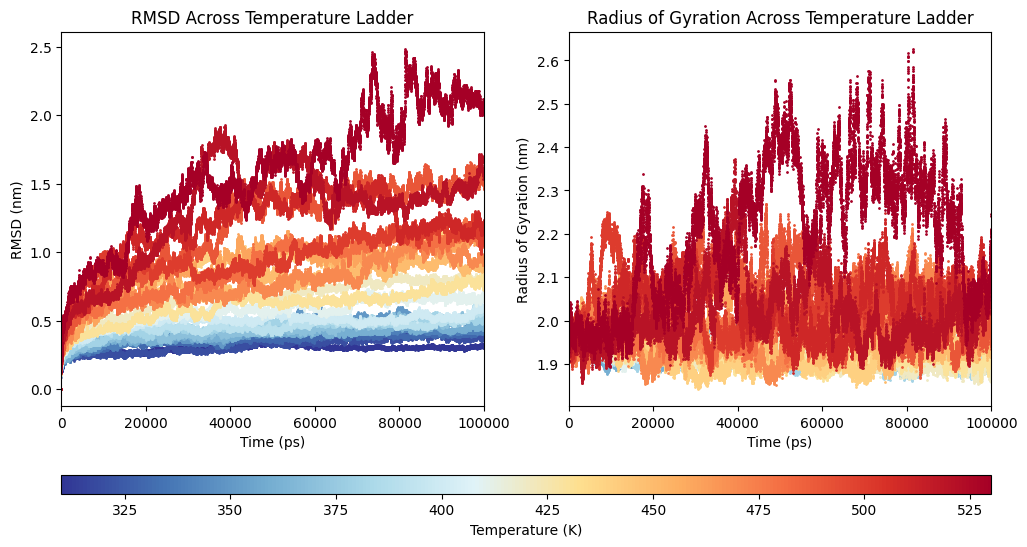

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# TEMPERATURES
# =========================================================

Ts = list(range(310, 531, 10))
norm = Normalize(vmin=min(Ts), vmax=max(Ts))

main_dir = "1b"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_Ts = []

for T in Ts:

    rmsd_file = os.path.join(main_dir, f"T{T}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"T{T}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for T{T}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_Ts.append(T)

print("Valid temperatures:", valid_Ts)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, T in enumerate(valid_Ts):

    color = CMAP(norm(T))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2,
        label=f"{T} K"
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Temperature Ladder")
ax1.set_xlim(0, 100000)

# =========================================================
# Rg
# =========================================================

for i, T in enumerate(valid_Ts):

    color = CMAP(norm(T))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2,
        label=f"{T} K"
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Temperature Ladder")
ax2.set_xlim(0, 100000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Temperature (K)")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## Potential Energy Extraction ⚡

Potential energy was extracted from `ener.edr` files across all temperature replicas (**310–530 K**) using `gmx energy`.

- Generated `potential.xvg` for each temperature
- Processing performed in parallel across replicas

✨ Potential energy trends were used to compare thermodynamic behavior across the temperature ladder.

In [ ]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  1b/TXXX/ener.edr
#   Output: 1b/TXXX/potential.xvg
# ============================================================

def run_cmd(cmd):
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(T):

    replica_dir = os.path.join(main_dir, f"T{T}")

    edr_file = os.path.join(replica_dir, "md.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ T{T}: missing ener.edr"

    print(f"▶️ Starting T{T}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ T{T}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "1b")

Ts = list(range(310, 531, 10))

# Run all temperatures at once
max_workers = len(Ts)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, T)
        for T in Ts
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all replicas.")

▶️ Starting T310
▶️ Starting T330
▶️ Starting T320
▶️ Starting T340
▶️ Starting T350
▶️ Starting T360
▶️ Starting T370
▶️ Starting T380
▶️ Starting T390
▶️ Starting T410
▶️ Starting T420
▶️ Starting T430
▶️ Starting T400
▶️ Starting T440
▶️ Starting T450
▶️ Starting T460
▶️ Starting T470
▶️ Starting T480
▶️ Starting T500
▶️ Starting T490
▶️ Starting T510
▶️ Starting T520
▶️ Starting T530


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


Statistics over 92785001 steps [ 0.0000 through 185570.0000 ps ], 1 data sets
All statistics are over 927851 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -443843         16    808.699   -95.6277  (kJ/mol)

Statistics over 92790001 steps [ 0.0000 through 185580.0000 ps ], 1 data sets
All statistics are over 927901 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -439033         33    823.429    -238.45  (kJ/mol)
✅ T350: potential.xvg written, 18558 frames
✅ T360: potential.xvg written, 18559 frames


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T370/md.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T370/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/1b/T370/md.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  D


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -374869         36    1045.85    155.207  (kJ/mol)
✅ T520: potential.xvg written, 10001 frames


...


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -416616         24    893.387   -123.142  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -385463         36    1000.63   -113.681  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -381938      

Reading energy frame   1500 time 15000.000         
GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)

Last energy frame read 10000 time 100000.000         
Last energy frame read 10000 time 100000.000         
Reading energy frame   1100 time 11000.000         
GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)

Last energy frame read 10000 time 100000.000         
Reading energy frame   5000 time 50000.000                        :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -429778         15    849.462   -58.8597  (kJ/mol)

Statistics over 84910001 steps [ 0.0000 through 169820.0000 ps ], 1 data sets
All statistics are over 849101 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -459088         19    765.439   -89.7004  (kJ/mol)
✅ T310: potential.xvg written, 16160 frames
✅ T420: potential.xvg written, 10001 frames

Statistics over 93245001 steps [ 0.0000 through 186490.0000 ps ], 1 data sets
All statistics are over 932451 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
---------------------------------

Last energy frame read 10000 time 100000.000         
Reading energy frame   4000 time 40000.000         
GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)

Last energy frame read 10000 time 100000.000         
Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)


GROMACS reminds you: "How wonderful that we have met with a paradox. Now we have some hope of making progress." (Niels Bohr)



✅ T510: potential.xvg written, 10001 frames
✅ T460: potential.xvg written, 10001 frames

🎉 Finished extracting potential energy for all replicas.


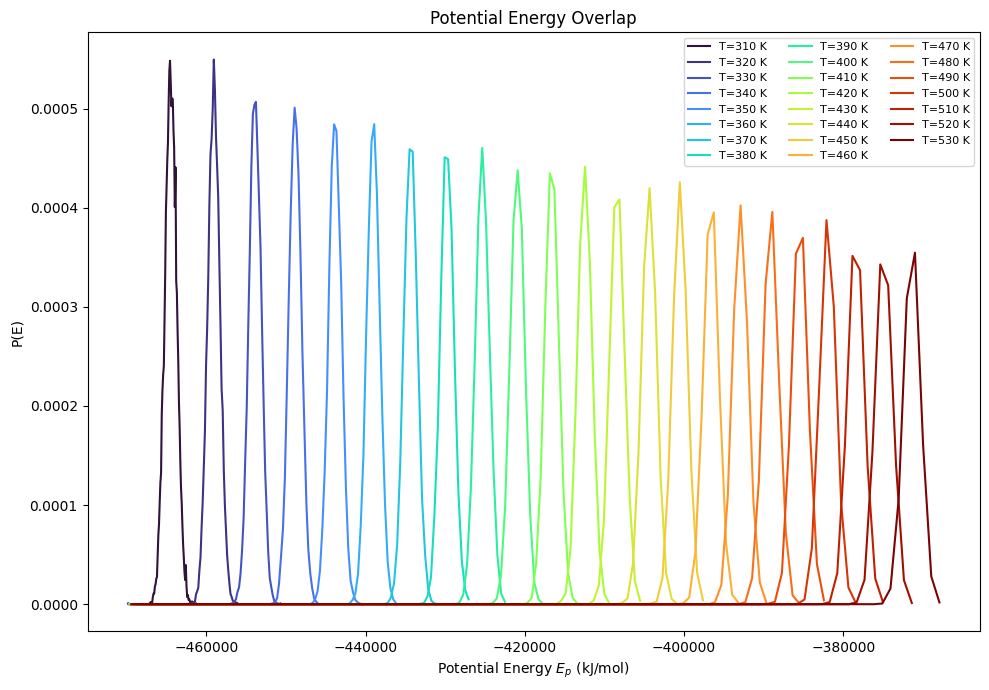

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  1b/TXXX/potential.xvg
# ============================================================

main_dir = "1b"
Ts = list(range(310, 531, 10))

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(Ts)))

plt.figure(figsize=(10, 7))

for i, T in enumerate(Ts):

    pot_file = os.path.join(main_dir, f"T{T}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"T={T} K"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

Inference 🔍

Potential energy distributions shift progressively toward higher energies with increasing temperature, consistent with greater thermal excitation of the protein system.

✨ Neighboring temperature windows show reasonable overlap, suggesting the **310–530 K ladder** provides continuous thermodynamic coverage suitable for refining the transition region and guiding subsequent enhanced sampling setup.

Additional: Notice that the energy distributions are smaller than 3PRG indicating that we need to move uptil 600 (in other words we need more energy to unfold as much as 3PRG)

# We have reached the END of Part1 please proceed to 2_6ONJ_HREMD.ipynb